# 04. Deep Dive — Nominal


## Notebook này làm gì

Phân tích taxonomy sản phẩm, brand và mức độ đóng góp của product/household.

### Nội dung đã thực hiện

- Top-N và Pareto số dòng theo department, commodity và subcommodity.
- Đóng góp SALES_VALUE theo department, commodity và department × commodity.
- So sánh National/Private theo catalog, số dòng, doanh thu và household reach.
- Đếm household distinct theo department và commodity.
- Phân tích product-level long-tail bằng rank-frequency và Pareto 80% số dòng.
- Pareto household theo SALES_VALUE, số dòng transaction và basket distinct.


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


In [2]:
raw_dir = Path("../data/raw/Dunnhumby")


In [3]:
product_taxonomy = pd.read_csv(
    raw_dir / "product.csv",
    usecols=[
        "PRODUCT_ID", "MANUFACTURER", "BRAND", "DEPARTMENT",
        "COMMODITY_DESC", "SUB_COMMODITY_DESC",
    ],
)
transaction_detail = pd.read_csv(
    raw_dir / "transaction_data.csv",
    usecols=[
        "household_key", "BASKET_ID", "PRODUCT_ID", "SALES_VALUE",
    ],
)


### 7.4. Category concentration và Pareto

Ba taxonomy `DEPARTMENT`, `COMMODITY_DESC`, `SUB_COMMODITY_DESC` được xếp hạng theo số dòng transaction. Coverage top-10 và Pareto vì vậy phản ánh mức độ tập trung của hoạt động mua, không chỉ số category trong product catalog.

In [4]:
CATEGORY_COLUMNS = ["DEPARTMENT", "COMMODITY_DESC", "SUB_COMMODITY_DESC"]
CATEGORY_TOP_N = 15
category_lookup = product_taxonomy.drop_duplicates("PRODUCT_ID").set_index("PRODUCT_ID")
for category_column in CATEGORY_COLUMNS:
    transaction_detail[category_column] = (
        transaction_detail["PRODUCT_ID"]
        .map(category_lookup[category_column])
        .fillna("<MISSING>")
        .astype("category")
    )

category_profiles = {}
category_coverage_rows = []
for category_column in CATEGORY_COLUMNS:
    line_counts = transaction_detail[category_column].value_counts(dropna=False)
    product_counts = (
        product_taxonomy[category_column]
        .fillna("<MISSING>")
        .value_counts(dropna=False)
    )
    profile = line_counts.rename("n_lines").to_frame()
    profile["n_products"] = profile.index.map(product_counts).fillna(0).astype("int64")
    profile["line_pct"] = profile["n_lines"] / profile["n_lines"].sum() * 100
    profile["cumulative_line_pct"] = profile["line_pct"].cumsum()
    profile.index.name = category_column
    category_profiles[category_column] = profile
    categories_to_80pct = int(
        np.searchsorted(profile["cumulative_line_pct"].to_numpy(), 80, side="left") + 1
    )
    category_coverage_rows.append({
        "category": category_column,
        "n_distinct": int(len(profile)),
        "top_10_line_pct": float(profile["line_pct"].head(10).sum()),
        "categories_to_80pct": categories_to_80pct,
    })
category_top10_coverage = pd.DataFrame(category_coverage_rows)
display(category_top10_coverage, *(profile.head(CATEGORY_TOP_N) for profile in category_profiles.values()))

,category,n_distinct,top_10_line_pct,categories_to_80pct
0,DEPARTMENT,44,98.137096,3
1,COMMODITY_DESC,308,25.713479,89
2,SUB_COMMODITY_DESC,2383,13.035899,383


,n_lines,n_products,line_pct,cumulative_line_pct
DEPARTMENT,,,,
GROCERY,1646076,39021,63.414713,63.414713
DRUG GM,277232,31529,10.680301,74.095014
PRODUCE,257290,3118,9.912040,84.007055
MEAT-PCKGD,111957,2427,4.313119,88.320173
MEAT,88416,2544,3.406207,91.726380
DELI,62787,2354,2.418855,94.145235
PASTRY,38179,2149,1.470838,95.616073
NUTRITION,32164,2914,1.239111,96.855184
KIOSK-GAS,22059,16,0.849818,97.705002


,n_lines,n_products,line_pct,cumulative_line_pct
COMMODITY_DESC,,,,
SOFT DRINKS,117532,1704,4.527894,4.527894
FLUID MILK PRODUCTS,85630,455,3.298877,7.826771
BAKED BREAD/BUNS/ROLLS,83232,1169,3.206494,11.033265
CHEESE,74885,1096,2.884928,13.918193
BAG SNACKS,67190,1523,2.588480,16.506673
FRZN MEAT/MEAT DINNERS,56064,1268,2.159853,18.666526
BEEF,48726,1109,1.877158,20.543685
SOUP,46135,978,1.777341,22.321025
YOGURT,44697,686,1.721942,24.042967


,n_lines,n_products,line_pct,cumulative_line_pct
SUB_COMMODITY_DESC,,,,
FLUID MILK WHITE ONLY,65764,194,2.533544,2.533544
SOFT DRINKS 12/18&15PK CAN CAR,39352,404,1.516027,4.049571
YOGURT NOT MULTI-PACKS,37440,512,1.442368,5.491938
SFT DRNK 2 LITER BTL CARB INCL,37273,343,1.435934,6.927872
BANANAS,30436,17,1.172540,8.100413
MAINSTREAM WHITE BREAD,27392,160,1.055271,9.155683
SHREDDED CHEESE,27343,287,1.053383,10.209066
CANDY BARS (SINGLES)(INCLUDING,26070,350,1.004341,11.213407
GASOLINE-REG UNLEADED,24962,35,0.961656,12.175063


- có 44 department nhưng chỉ 3 cái đã chiếm tới 80%, top 10 thì chiếm tới 98%

- 89 

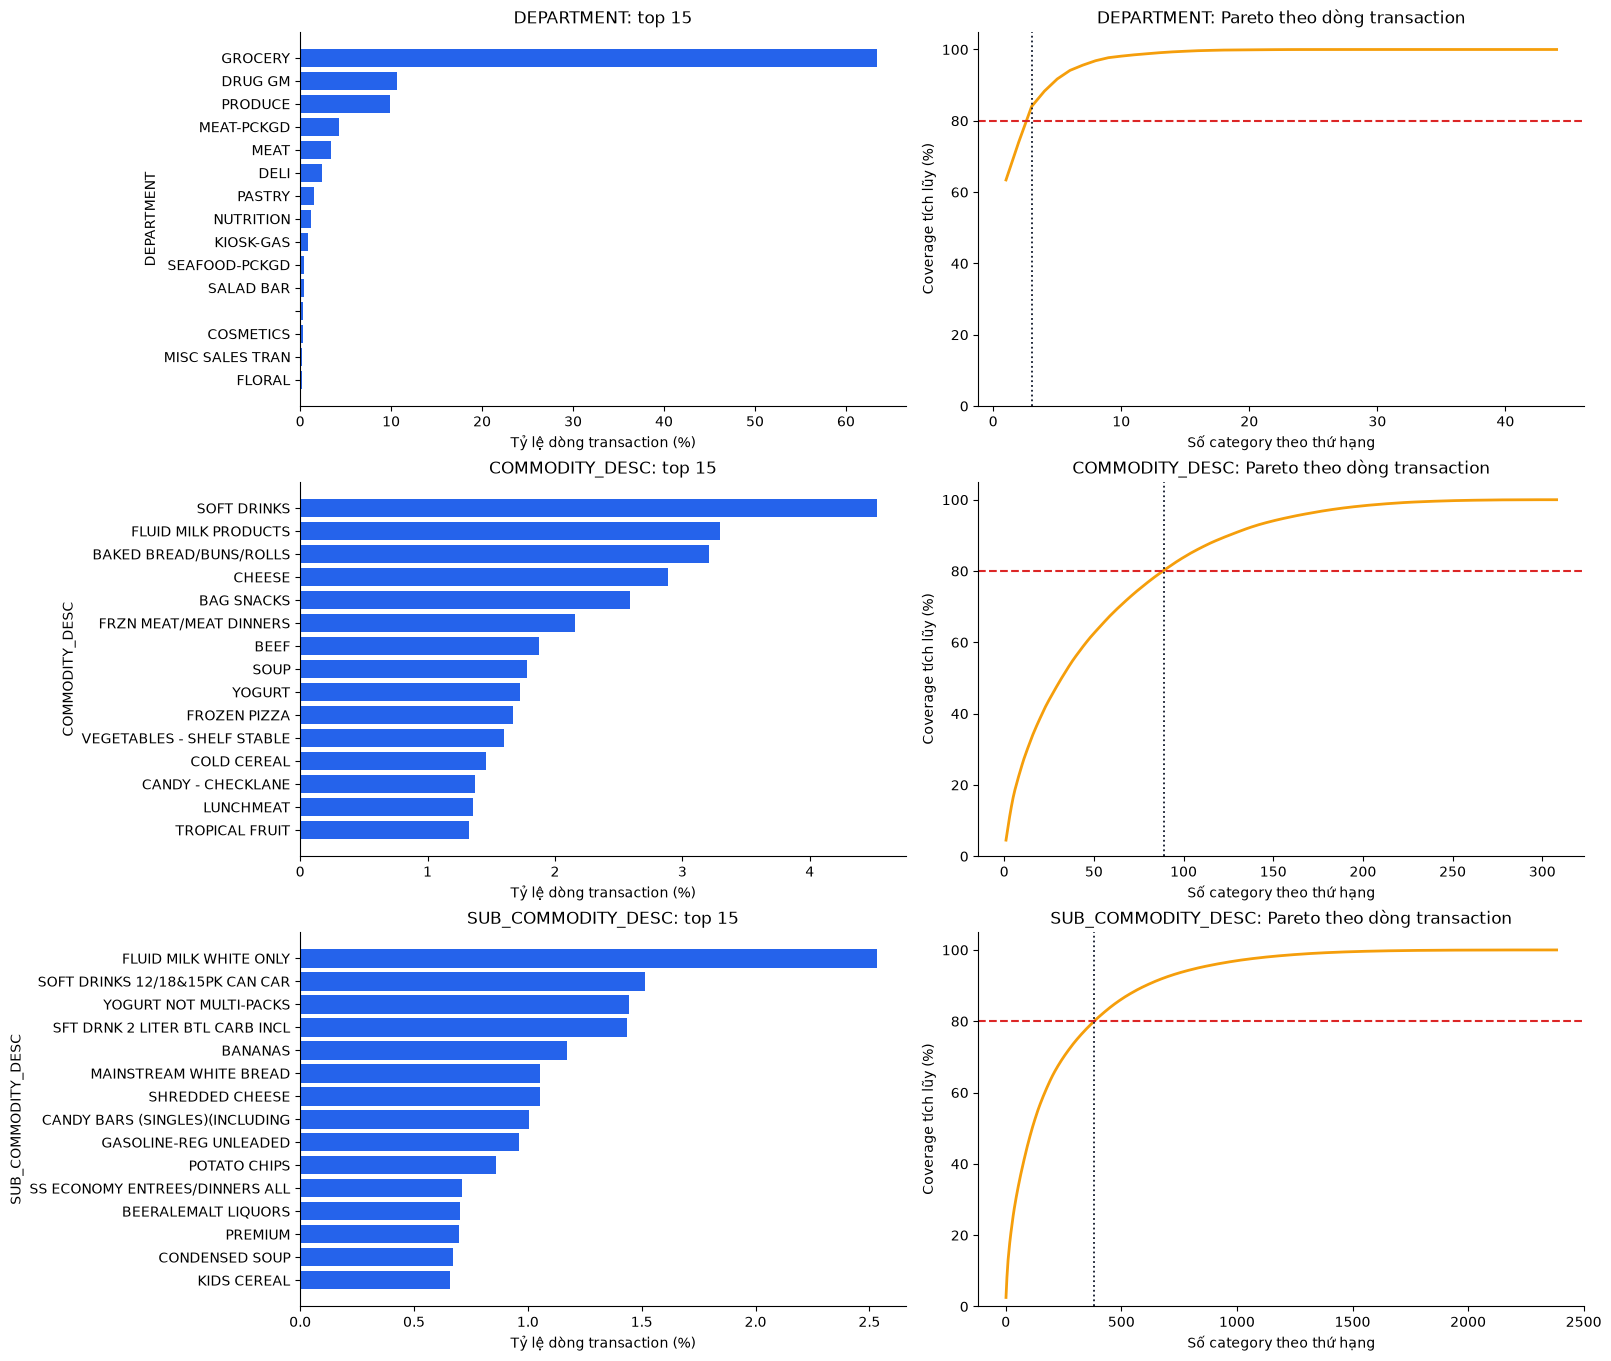

In [5]:
category_figure, category_axes = plt.subplots(
    len(CATEGORY_COLUMNS), 2,
    figsize=(16, 4.5 * len(CATEGORY_COLUMNS)),
    layout="constrained",
)
for row_index, category_column in enumerate(CATEGORY_COLUMNS):
    profile = category_profiles[category_column]
    top_axis, pareto_axis = category_axes[row_index]
    top_profile = profile.head(CATEGORY_TOP_N).sort_values("n_lines")
    top_axis.barh(
        [str(value) for value in top_profile.index],
        top_profile["line_pct"],
        color="#2563EB",
    )
    top_axis.set(
        title=f"{category_column}: top {CATEGORY_TOP_N}",
        xlabel="Tỷ lệ dòng transaction (%)", ylabel=category_column,
    )
    category_rank = np.arange(1, len(profile) + 1)
    pareto_axis.plot(
        category_rank, profile["cumulative_line_pct"],
        color="#F59E0B", linewidth=2,
    )
    pareto_axis.axhline(80, color="#DC2626", linestyle="--", linewidth=1.5)
    pareto_axis.axvline(
        int(category_top10_coverage.loc[
            category_top10_coverage["category"].eq(category_column),
            "categories_to_80pct",
        ].iloc[0]),
        color="#0F172A", linestyle=":", linewidth=1.3,
    )
    pareto_axis.set(
        title=f"{category_column}: Pareto theo dòng transaction",
        xlabel="Số category theo thứ hạng", ylabel="Coverage tích lũy (%)",
        ylim=(0, 105),
    )
    for axis in (top_axis, pareto_axis):
        axis.spines[["top", "right"]].set_visible(False)
plt.show()

### 7.5. Đóng góp doanh số (SALES_VALUE) theo Department, Commodity và Department × Commodity

Kiểm tra xem ngành hàng (`DEPARTMENT`), nhóm mặt hàng (`COMMODITY_DESC` - thường được gọi là commodity / community), và cặp kết hợp (`DEPARTMENT × COMMODITY_DESC`) nào tạo ra tổng doanh số `SALES_VALUE` lớn nhất.

In [6]:
# Đảm bảo SALES_VALUE là kiểu số hợp lệ
transaction_detail["SALES_VALUE"] = pd.to_numeric(transaction_detail["SALES_VALUE"], errors="coerce")
total_sales_overall = float(transaction_detail["SALES_VALUE"].sum())

# 1. Top DEPARTMENT tạo ra SALES_VALUE nhiều nhất
sales_by_dept = (
    transaction_detail
    .groupby("DEPARTMENT", observed=True)
    .agg(
        total_sales_value=("SALES_VALUE", "sum"),
        mean_sales_value=("SALES_VALUE", "mean"),
        n_lines=("SALES_VALUE", "count"),
    )
    .assign(sales_pct=lambda df: df["total_sales_value"] / total_sales_overall * 100)
    .sort_values(by="total_sales_value", ascending=False)
    .assign(cum_sales_pct=lambda df: df["sales_pct"].cumsum())
)

# 2. Top COMMODITY_DESC (Commodity / Community) tạo ra SALES_VALUE nhiều nhất
sales_by_commodity = (
    transaction_detail
    .groupby("COMMODITY_DESC", observed=True)
    .agg(
        total_sales_value=("SALES_VALUE", "sum"),
        mean_sales_value=("SALES_VALUE", "mean"),
        n_lines=("SALES_VALUE", "count"),
    )
    .assign(sales_pct=lambda df: df["total_sales_value"] / total_sales_overall * 100)
    .sort_values(by="total_sales_value", ascending=False)
    .assign(cum_sales_pct=lambda df: df["sales_pct"].cumsum())
)

# 3. Top DEPARTMENT × COMMODITY_DESC tạo ra SALES_VALUE nhiều nhất
sales_by_dept_commodity = (
    transaction_detail
    .groupby(["DEPARTMENT", "COMMODITY_DESC"], observed=True)
    .agg(
        total_sales_value=("SALES_VALUE", "sum"),
        mean_sales_value=("SALES_VALUE", "mean"),
        n_lines=("SALES_VALUE", "count"),
    )
    .assign(sales_pct=lambda df: df["total_sales_value"] / total_sales_overall * 100)
    .sort_values(by="total_sales_value", ascending=False)
    .assign(cum_sales_pct=lambda df: df["sales_pct"].cumsum())
)

print("=== TOP 10 DEPARTMENT TẠO RA SALES_VALUE NHIỀU NHẤT ===")
display(sales_by_dept.head(10))

print("\n=== TOP 10 COMMODITY (COMMUNITY) TẠO RA SALES_VALUE NHIỀU NHẤT ===")
display(sales_by_commodity.head(10))

print("\n=== TOP 10 DEPARTMENT × COMMODITY TẠO RA SALES_VALUE NHIỀU NHẤT ===")
display(sales_by_dept_commodity.head(10))


=== TOP 10 DEPARTMENT TẠO RA SALES_VALUE NHIỀU NHẤT ===


,total_sales_value,mean_sales_value,n_lines,sales_pct,cum_sales_pct
DEPARTMENT,,,,,
GROCERY,4093814.14,2.487014,1646076,50.807731,50.807731
DRUG GM,1055358.03,3.806768,277232,13.097895,63.905625
PRODUCE,557452.11,2.166630,257290,6.918457,70.824082
MEAT,548786.81,6.206872,88416,6.810913,77.634995
KIOSK-GAS,544222.28,24.671213,22059,6.754263,84.389259
MEAT-PCKGD,412436.77,3.683886,111957,5.118693,89.507951
DELI,260866.51,4.154785,62787,3.237576,92.745528
PASTRY,121739.86,3.188660,38179,1.510896,94.256423
MISC SALES TRAN,119960.04,19.828106,6050,1.488807,95.745230



=== TOP 10 COMMODITY (COMMUNITY) TẠO RA SALES_VALUE NHIỀU NHẤT ===


,total_sales_value,mean_sales_value,n_lines,sales_pct,cum_sales_pct
COMMODITY_DESC,,,,,
COUPON/MISC ITEMS,639878.56,22.976716,27849,7.941440,7.941440
SOFT DRINKS,327647.30,2.787728,117532,4.066383,12.007822
BEEF,312103.22,6.405271,48726,3.873468,15.881290
FLUID MILK PRODUCTS,205356.05,2.398179,85630,2.548644,18.429934
CHEESE,189528.18,2.530923,74885,2.352207,20.782141
FRZN MEAT/MEAT DINNERS,160517.17,2.863106,56064,1.992155,22.774296
BAG SNACKS,148375.16,2.208292,67190,1.841462,24.615758
BEERS/ALES,147344.45,8.273130,17810,1.828670,26.444429
FROZEN PIZZA,146037.25,3.367862,43362,1.812447,28.256876



=== TOP 10 DEPARTMENT × COMMODITY TẠO RA SALES_VALUE NHIỀU NHẤT ===


total_sales_value  mean_sales_value  \
DEPARTMENT COMMODITY_DESC                                                
KIOSK-GAS  COUPON/MISC ITEMS               514685.72         25.390248   
GROCERY    SOFT DRINKS                     327647.30          2.787728   
MEAT       BEEF                            312103.22          6.405271   
GROCERY    FLUID MILK PRODUCTS             205356.05          2.398179   
           CHEESE                          189528.18          2.530923   
           FRZN MEAT/MEAT DINNERS          160517.17          2.863106   
           BAG SNACKS                      148375.16          2.208292   
           BEERS/ALES                      147309.68          8.272571   
           FROZEN PIZZA                    146037.25          3.367862   
           BAKED BREAD/BUNS/ROLLS          145930.85          1.753302   

                                   n_lines  sales_pct  cum_sales_pct  
DEPARTMENT COMMODITY_DESC                                             
KIOSK-GAS  COUPON/MISC ITEMS         20271   6.387689       6.387689  
GROCERY    SOFT DRINKS              117532   4.066383      10.454072  
MEAT       BEEF                      48726   3.873468      14.327540  
GROCERY    FLUID MILK PRODUCTS       85630   2.548644      16.876184  
           CHEESE                    74885   2.352207      19.228391  
           FRZN MEAT/MEAT DINNERS    56064   1.992155      21.220546  
           BAG SNACKS                67190   1.841462      23.062008  
           BEERS/ALES                17807   1.828239      24.890247  
           FROZEN PIZZA              43362   1.812447      26.702694  
           BAKED BREAD/BUNS/ROLLS    83232   1.811127      28.513821

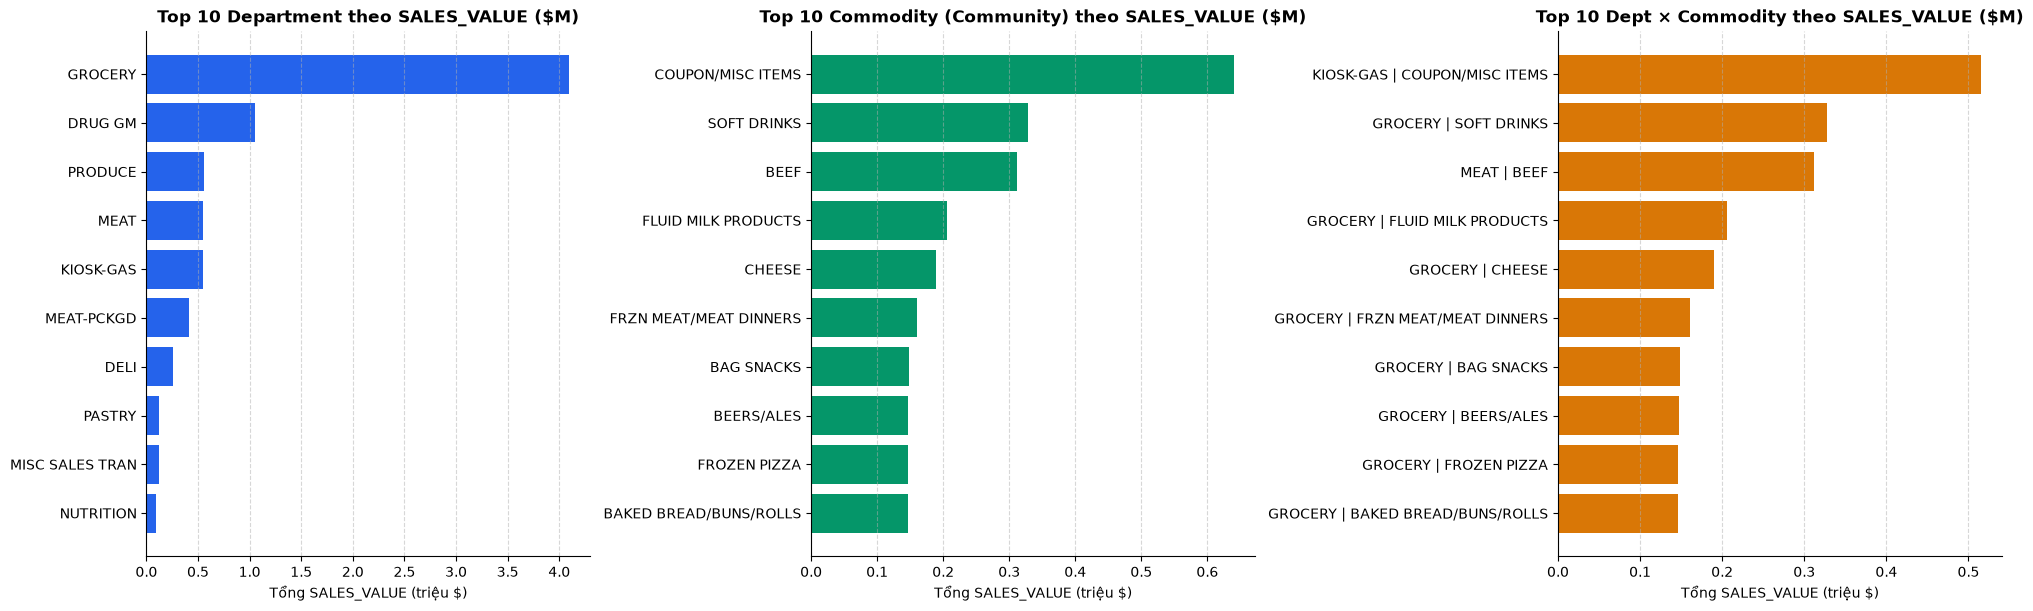

In [7]:
# Trực quan hóa Top 10 của từng cấp phân loại theo SALES_VALUE
fig_sales, axes_sales = plt.subplots(1, 3, figsize=(20, 6), layout="constrained")

# 1. Top Department
top_d = sales_by_dept.head(10).sort_values("total_sales_value")
axes_sales[0].barh([str(x) for x in top_d.index], top_d["total_sales_value"] / 1e6, color="#2563EB")
axes_sales[0].set_title("Top 10 Department theo SALES_VALUE ($M)", fontsize=12, fontweight="bold")
axes_sales[0].set_xlabel("Tổng SALES_VALUE (triệu $)")

# 2. Top Commodity
top_c = sales_by_commodity.head(10).sort_values("total_sales_value")
axes_sales[1].barh([str(x) for x in top_c.index], top_c["total_sales_value"] / 1e6, color="#059669")
axes_sales[1].set_title("Top 10 Commodity (Community) theo SALES_VALUE ($M)", fontsize=12, fontweight="bold")
axes_sales[1].set_xlabel("Tổng SALES_VALUE (triệu $)")

# 3. Top Department x Commodity
top_dc = sales_by_dept_commodity.head(10).sort_values("total_sales_value")
dc_labels = [f"{d} | {c}" for d, c in top_dc.index]
axes_sales[2].barh(dc_labels, top_dc["total_sales_value"] / 1e6, color="#D97706")
axes_sales[2].set_title("Top 10 Dept × Commodity theo SALES_VALUE ($M)", fontsize=12, fontweight="bold")
axes_sales[2].set_xlabel("Tổng SALES_VALUE (triệu $)")

for ax in axes_sales:
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", linestyle="--", alpha=0.5)

plt.show()


#### Kết luận phân tích doanh số (SALES_VALUE):
- **Department tạo ra `SALES_VALUE` nhiều nhất**: **`GROCERY`** đứng đầu áp đảo với **$4,093,814.14** (chiếm **50.81%** tổng doanh thu toàn hệ thống). Theo sau là **`DRUG GM`** ($1,055,358.03 - **13.10%**), **`PRODUCE`** ($557,452.11 - **6.92%**), **`MEAT`** ($548,786.81 - **6.81%**) và **`KIOSK-GAS`** ($544,222.28 - **6.75%**). Top 5 ngành hàng này chiếm đến **84.39%** tổng doanh thu.
- **Commodity (Community) tạo ra `SALES_VALUE` nhiều nhất**: **`COUPON/MISC ITEMS`** dẫn đầu với **$639,878.56** (chiếm **7.94%** tổng doanh số, trong đó phần lớn là doanh thu nhiên liệu/xăng tại Kiosk Gas). Kế tiếp là các ngành hàng thực phẩm thiết yếu: **`SOFT DRINKS`** ($327,647.30 - **4.07%**), **`BEEF`** ($312,103.22 - **3.87%**), **`FLUID MILK PRODUCTS`** ($205,356.05 - **2.55%**) và **`CHEESE`** ($189,528.18 - **2.35%**).
- **Department × Commodity tạo ra `SALES_VALUE` nhiều nhất**: Cặp kết hợp **`KIOSK-GAS | COUPON/MISC ITEMS`** tạo ra doanh số lớn nhất toàn chuỗi với **$514,685.72** (chiếm **6.39%** tổng sales). Xếp sau lần lượt là các cặp chủ lực: **`GROCERY | SOFT DRINKS`** ($327,647.30 - **4.07%**), **`MEAT | BEEF`** ($312,103.22 - **3.87%**), **`GROCERY | FLUID MILK PRODUCTS`** ($205,356.05 - **2.55%**) và **`GROCERY | CHEESE`** ($189,528.18 - **2.35%**).


### 7.6. National và Private Brand

So sánh hai loại `BRAND` theo độ rộng catalog, số dòng transaction, doanh thu và tỷ lệ household có mua.


,n_lines,n_baskets,n_households,total_sales_value,n_catalog_products,catalog_product_pct,line_pct,sales_pct,household_reach_pct
BRAND,,,,,,,,,
National,1849560,238309,2500,5820201.75,78537,85.04001,71.253889,72.233676,100.00
Private,746172,195721,2496,2237261.33,13816,14.95999,28.746111,27.766324,99.84


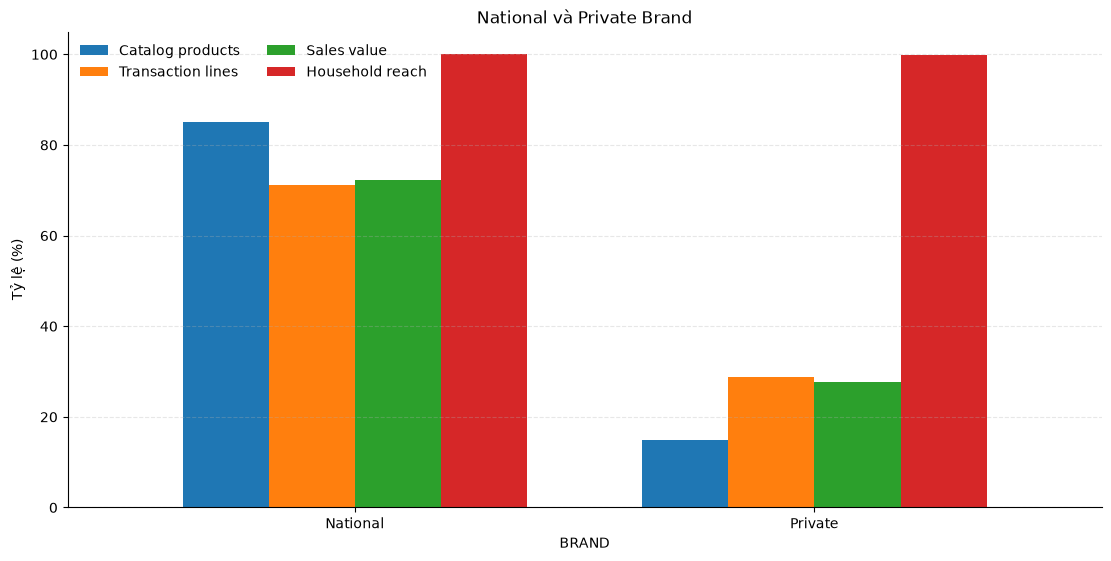

In [8]:
transaction_detail["BRAND"] = (
    transaction_detail["PRODUCT_ID"]
    .map(category_lookup["BRAND"])
    .fillna("<MISSING>")
    .astype("category")
)
total_households = transaction_detail["household_key"].nunique()
brand_catalog_counts = product_taxonomy["BRAND"].value_counts(dropna=False)
brand_comparison = (
    transaction_detail
    .groupby("BRAND", observed=True, dropna=False)
    .agg(
        n_lines=("PRODUCT_ID", "size"),
        n_baskets=("BASKET_ID", "nunique"),
        n_households=("household_key", "nunique"),
        total_sales_value=("SALES_VALUE", "sum"),
    )
    .sort_values("n_lines", ascending=False)
)
brand_comparison["n_catalog_products"] = (
    brand_comparison.index.map(brand_catalog_counts).astype("int64")
)
brand_comparison["catalog_product_pct"] = (
    brand_comparison["n_catalog_products"]
    / brand_comparison["n_catalog_products"].sum() * 100
)
brand_comparison["line_pct"] = (
    brand_comparison["n_lines"] / brand_comparison["n_lines"].sum() * 100
)
brand_comparison["sales_pct"] = (
    brand_comparison["total_sales_value"]
    / brand_comparison["total_sales_value"].sum() * 100
)
brand_comparison["household_reach_pct"] = (
    brand_comparison["n_households"] / total_households * 100
)
display(brand_comparison)

brand_metric_columns = [
    "catalog_product_pct", "line_pct",
    "sales_pct", "household_reach_pct",
]
brand_comparison_figure, brand_comparison_axis = plt.subplots(
    figsize=(11, 5.5), layout="constrained"
)
brand_comparison[brand_metric_columns].plot(
    kind="bar", ax=brand_comparison_axis, width=0.75,
)
brand_comparison_axis.set(
    title="National và Private Brand",
    xlabel="BRAND",
    ylabel="Tỷ lệ (%)",
)
brand_comparison_axis.tick_params(axis="x", rotation=0)
brand_comparison_axis.spines[["top", "right"]].set_visible(False)
brand_comparison_axis.grid(axis="y", linestyle="--", alpha=0.3)
brand_comparison_axis.legend(
    ["Catalog products", "Transaction lines", "Sales value", "Household reach"],
    frameon=False, ncol=2,
)
plt.show()


### 7.7. Số household theo Department và Commodity

Đếm `household_key` distinct có mua ít nhất một sản phẩm trong từng `DEPARTMENT` hoặc `COMMODITY_DESC`. Horizontal bar chart hiển thị top 20 để nhãn ngành hàng dài vẫn dễ đọc.


,n_households,n_baskets,n_lines,n_products,household_reach_pct
DEPARTMENT,,,,,
GROCERY,2500,215411,1646076,39019,100.00
DRUG GM,2491,118195,277232,31523,99.64
PRODUCE,2456,89026,257290,3117,98.24
MEAT-PCKGD,2392,58466,111957,2427,95.68
MEAT,2351,53401,88416,2544,94.04
PASTRY,2281,30099,38179,2149,91.24
DELI,2248,35639,62787,2354,89.92
NUTRITION,1719,16820,32164,2913,68.76
SEAFOOD-PCKGD,1654,8873,11216,563,66.16


,n_households,n_baskets,n_lines,n_products,household_reach_pct
COMMODITY_DESC,,,,,
FLUID MILK PRODUCTS,2421,69278,85630,455,96.84
SOFT DRINKS,2405,71699,117532,1704,96.20
BAKED BREAD/BUNS/ROLLS,2400,60311,83232,1169,96.00
CHEESE,2350,46898,74885,1096,94.00
BAG SNACKS,2348,42037,67190,1523,93.92
BEEF,2238,36733,48726,1109,89.52
EGGS,2231,27886,28420,121,89.24
SOUP,2195,23594,46135,978,87.80
CRACKERS/MISC BKD FD,2193,22722,29723,820,87.72


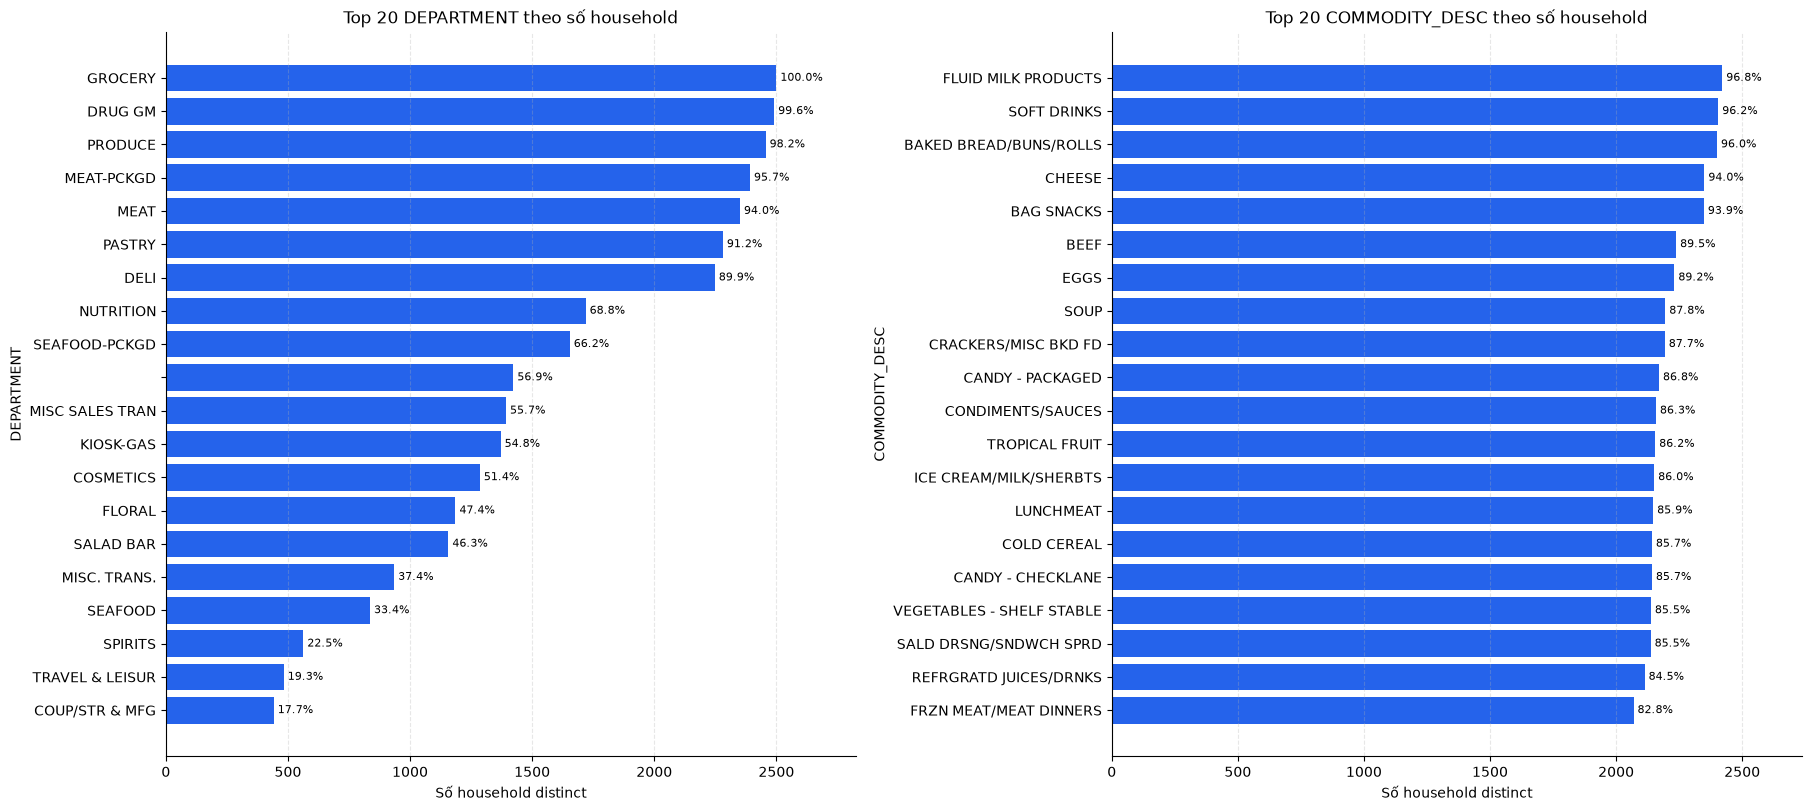

In [9]:
HOUSEHOLD_CATEGORY_COLUMNS = ["DEPARTMENT", "COMMODITY_DESC"]
household_category_profiles = {}
for category_column in HOUSEHOLD_CATEGORY_COLUMNS:
    household_profile = (
        transaction_detail
        .groupby(category_column, observed=True, dropna=False)
        .agg(
            n_households=("household_key", "nunique"),
            n_baskets=("BASKET_ID", "nunique"),
            n_lines=("PRODUCT_ID", "size"),
            n_products=("PRODUCT_ID", "nunique"),
        )
        .sort_values(["n_households", "n_lines"], ascending=False)
    )
    household_profile["household_reach_pct"] = (
        household_profile["n_households"] / total_households * 100
    )
    household_category_profiles[category_column] = household_profile

display(
    *(
        profile.head(20)
        for profile in household_category_profiles.values()
    )
)

household_category_figure, household_category_axes = plt.subplots(
    1, 2, figsize=(18, 8), layout="constrained"
)
for axis, category_column in zip(
    household_category_axes, HOUSEHOLD_CATEGORY_COLUMNS, strict=True
):
    top_household_profile = (
        household_category_profiles[category_column]
        .head(20)
        .sort_values("n_households")
    )
    bars = axis.barh(
        [str(value) for value in top_household_profile.index],
        top_household_profile["n_households"],
        color="#2563EB",
    )
    for bar, reach_pct in zip(
        bars, top_household_profile["household_reach_pct"], strict=True
    ):
        axis.text(
            bar.get_width(),
            bar.get_y() + bar.get_height() / 2,
            f" {reach_pct:.1f}%",
            va="center",
            fontsize=8,
        )
    axis.set(
        title=f"Top 20 {category_column} theo số household",
        xlabel="Số household distinct",
        ylabel=category_column,
    )
    axis.margins(x=0.13)
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="x", linestyle="--", alpha=0.3)
plt.show()


### 7.8. Product-level long-tail

Mỗi `PRODUCT_ID` được xếp hạng theo số dòng transaction. Rank-frequency trên thang log–log cho thấy hình dạng long-tail; đường Pareto cho biết cần bao nhiêu sản phẩm để bao phủ 80% số dòng.


,value
n_active_products,92339.000000
products_to_80pct_lines,10680.000000
products_to_80pct_pct_of_active_products,11.566077
products_with_one_line,33614.000000
products_with_one_line_pct,36.402820


,n_lines,n_baskets,n_households,total_sales_value,line_pct,cumulative_line_pct,rank
PRODUCT_ID,,,,,,,
1082185,29778,29778,2069,29482.00,1.147191,1.147191,1
6534178,19820,19820,1312,503867.11,0.763561,1.910752,2
1029743,14430,14430,1387,41072.06,0.555913,2.466665,3
995242,12542,12542,1465,26502.46,0.483178,2.949842,4
1106523,9826,9826,1040,27818.44,0.378544,3.328387,5
981760,9126,9126,1629,11693.65,0.351577,3.679964,6
1133018,7315,7315,1078,14942.36,0.281809,3.961773,7
883404,6904,6904,1249,8610.46,0.265975,4.227748,8
951590,6138,6138,870,12385.27,0.236465,4.464213,9


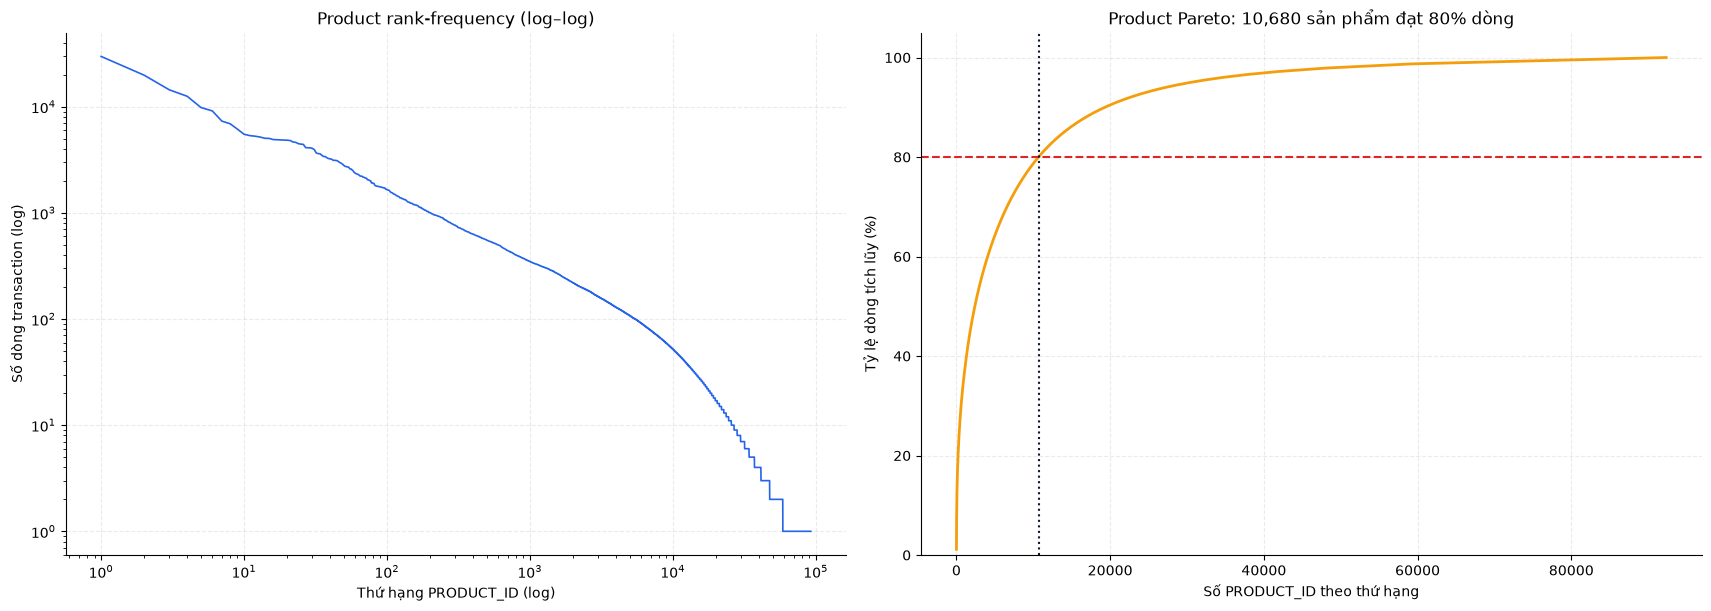

In [10]:
product_activity = (
    transaction_detail
    .groupby("PRODUCT_ID", observed=True, dropna=False)
    .agg(
        n_lines=("PRODUCT_ID", "size"),
        n_baskets=("BASKET_ID", "nunique"),
        n_households=("household_key", "nunique"),
        total_sales_value=("SALES_VALUE", "sum"),
    )
    .sort_values(["n_lines", "n_households"], ascending=False)
)
product_activity["line_pct"] = (
    product_activity["n_lines"] / product_activity["n_lines"].sum() * 100
)
product_activity["cumulative_line_pct"] = (
    product_activity["line_pct"].cumsum()
)
product_activity["rank"] = np.arange(1, len(product_activity) + 1)
products_to_80pct = int(
    np.searchsorted(
        product_activity["cumulative_line_pct"].to_numpy(),
        80,
        side="left",
    ) + 1
)
product_long_tail_summary = pd.Series({
    "n_active_products": len(product_activity),
    "products_to_80pct_lines": products_to_80pct,
    "products_to_80pct_pct_of_active_products": (
        products_to_80pct / len(product_activity) * 100
    ),
    "products_with_one_line": int(product_activity["n_lines"].eq(1).sum()),
    "products_with_one_line_pct": float(
        product_activity["n_lines"].eq(1).mean() * 100
    ),
}, name="value").to_frame()
display(product_long_tail_summary, product_activity.head(20))

product_long_tail_figure, product_long_tail_axes = plt.subplots(
    1, 2, figsize=(17, 6), layout="constrained"
)
product_long_tail_axes[0].plot(
    product_activity["rank"],
    product_activity["n_lines"],
    color="#2563EB",
    linewidth=1.2,
)
product_long_tail_axes[0].set_xscale("log")
product_long_tail_axes[0].set_yscale("log")
product_long_tail_axes[0].set(
    title="Product rank-frequency (log–log)",
    xlabel="Thứ hạng PRODUCT_ID (log)",
    ylabel="Số dòng transaction (log)",
)
product_long_tail_axes[1].plot(
    product_activity["rank"],
    product_activity["cumulative_line_pct"],
    color="#F59E0B",
    linewidth=2,
)
product_long_tail_axes[1].axhline(
    80, color="#DC2626", linestyle="--", linewidth=1.5
)
product_long_tail_axes[1].axvline(
    products_to_80pct, color="#0F172A", linestyle=":", linewidth=1.5
)
product_long_tail_axes[1].set(
    title=f"Product Pareto: {products_to_80pct:,} sản phẩm đạt 80% dòng",
    xlabel="Số PRODUCT_ID theo thứ hạng",
    ylabel="Tỷ lệ dòng tích lũy (%)",
    ylim=(0, 105),
)
for axis in product_long_tail_axes:
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(linestyle="--", alpha=0.25)
plt.show()


### 7.9. Pareto đóng góp của household

Xếp hạng `household_key` riêng theo tổng `SALES_VALUE`, số dòng transaction và số `BASKET_ID` distinct. Mỗi Pareto curve đánh dấu số household cần để đạt 80% tổng giá trị của chỉ tiêu tương ứng.


,metric,n_households,households_to_80pct,households_to_80pct_pct,top_10_household_contribution_pct,top_100_household_contribution_pct
0,total_sales_value,2500,1101,44.04,2.842767,17.843768
1,n_lines,2500,1126,45.04,2.370391,16.408974
2,n_baskets,2500,1172,46.88,3.607080,18.472317


,total_sales_value,contribution_pct,cumulative_contribution_pct,rank
household_key,,,,
1023,38319.79,0.475581,0.475581,1
1609,27859.68,0.345762,0.821344,2
2322,23646.92,0.293478,1.114822,3
1453,21661.29,0.268835,1.383657,4
2459,20671.50,0.256551,1.640208,5
1430,20352.99,0.252598,1.892806,6
718,19299.86,0.239528,2.132334,7
707,19194.42,0.238219,2.370553,8
1653,19153.75,0.237714,2.608268,9


,n_lines,contribution_pct,cumulative_contribution_pct,rank
household_key,,,,
718,6851,0.263933,0.263933,1
2459,6646,0.256036,0.519969,2
1609,6625,0.255227,0.775196,3
1111,6576,0.253339,1.028535,4
1453,6561,0.252761,1.281296,5
982,5806,0.223675,1.504970,6
2322,5692,0.219283,1.724254,7
371,5669,0.218397,1.942650,8
1489,5586,0.215199,2.157850,9


,n_baskets,contribution_pct,cumulative_contribution_pct,rank
household_key,,,,
1510,1300,0.470190,0.470190,1
900,1223,0.442340,0.912530,2
2337,1210,0.437638,1.350169,3
1795,1138,0.411597,1.761766,4
2459,971,0.351196,2.112961,5
762,886,0.320453,2.433414,6
1901,852,0.308155,2.741569,7
1467,835,0.302007,3.043576,8
1228,797,0.288263,3.331838,9


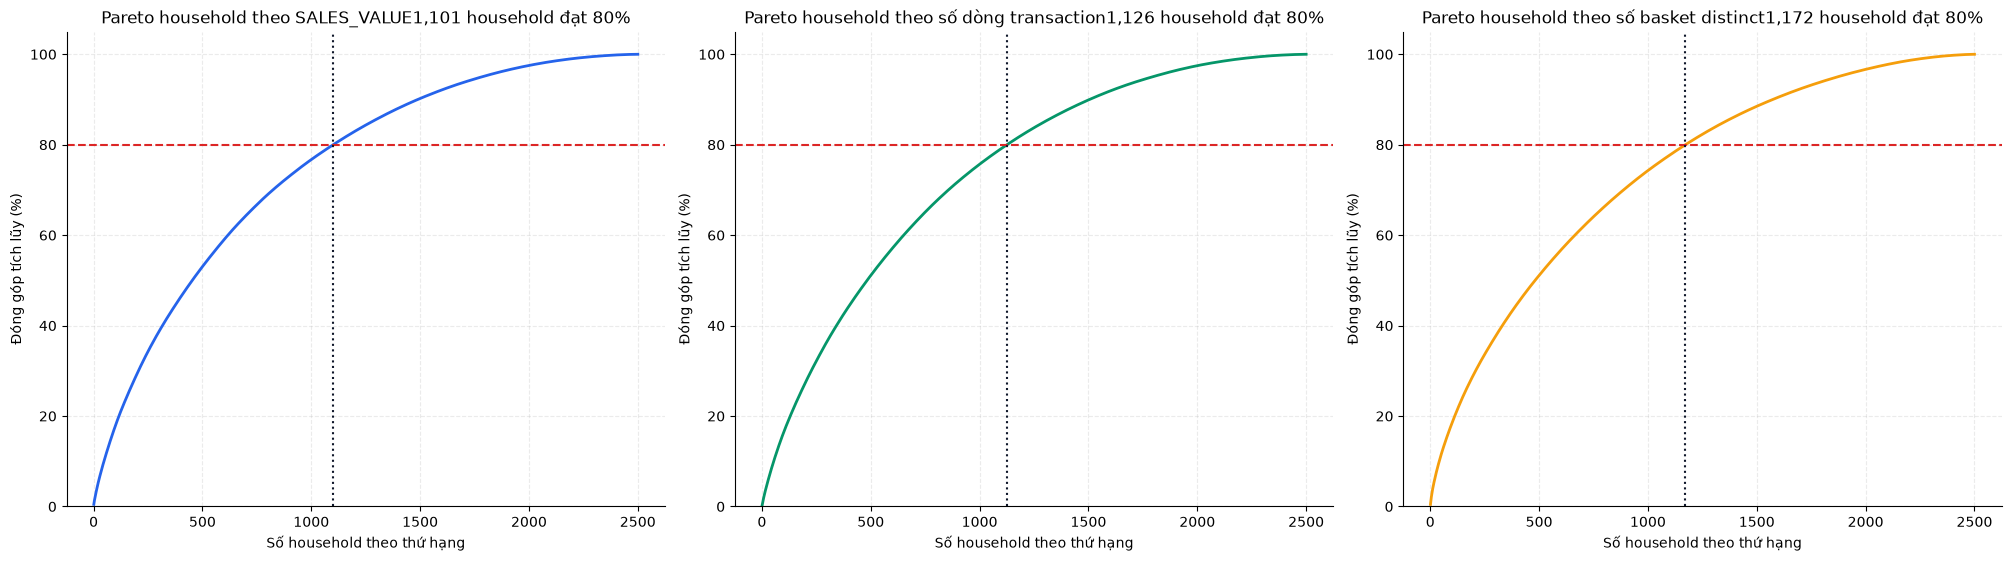

In [12]:
household_contribution = (
    transaction_detail
    .dropna(subset=["household_key"])
    .groupby("household_key", observed=True)
    .agg(
        total_sales_value=("SALES_VALUE", "sum"),
        n_lines=("PRODUCT_ID", "size"),
        n_baskets=("BASKET_ID", "nunique"),
    )
)

HOUSEHOLD_PARETO_METRICS = [
    ("total_sales_value", "SALES_VALUE", "#2563EB"),
    ("n_lines", "số dòng transaction", "#059669"),
    ("n_baskets", "số basket distinct", "#F59E0B"),
]
household_pareto_profiles = {}
household_pareto_summary_rows = []

for metric, metric_label, _ in HOUSEHOLD_PARETO_METRICS:
    profile = (
        household_contribution[[metric]]
        .sort_values(metric, ascending=False)
        .copy()
    )
    metric_total = float(profile[metric].sum())
    profile["contribution_pct"] = profile[metric] / metric_total * 100
    profile["cumulative_contribution_pct"] = profile["contribution_pct"].cumsum()
    profile["rank"] = np.arange(1, len(profile) + 1)
    households_to_80pct = int(
        np.searchsorted(
            profile["cumulative_contribution_pct"].to_numpy(),
            80,
            side="left",
        ) + 1
    )
    household_pareto_profiles[metric] = profile
    household_pareto_summary_rows.append({
        "metric": metric,
        "n_households": len(profile),
        "households_to_80pct": households_to_80pct,
        "households_to_80pct_pct": households_to_80pct / len(profile) * 100,
        "top_10_household_contribution_pct": float(
            profile["contribution_pct"].head(10).sum()
        ),
        "top_100_household_contribution_pct": float(
            profile["contribution_pct"].head(100).sum()
        ),
    })

household_pareto_summary = pd.DataFrame(household_pareto_summary_rows)
display(
    household_pareto_summary,
    *(profile.head(20) for profile in household_pareto_profiles.values()),
)

household_pareto_figure, household_pareto_axes = plt.subplots(
    1, 3, figsize=(20, 5.5), layout="constrained"
)
for axis, (metric, metric_label, color) in zip(
    household_pareto_axes, HOUSEHOLD_PARETO_METRICS, strict=True
):
    profile = household_pareto_profiles[metric]
    households_to_80pct = int(
        household_pareto_summary.loc[
            household_pareto_summary["metric"].eq(metric),
            "households_to_80pct",
        ].iloc[0]
    )
    axis.plot(
        profile["rank"],
        profile["cumulative_contribution_pct"],
        color=color,
        linewidth=2,
    )
    axis.axhline(80, color="#DC2626", linestyle="--", linewidth=1.5)
    axis.axvline(
        households_to_80pct,
        color="#0F172A",
        linestyle=":",
        linewidth=1.5,
    )
    axis.set(
        title=(
            f"Pareto household theo {metric_label}\n"
            f"{households_to_80pct:,} household đạt 80%"
        ),
        xlabel="Số household theo thứ hạng",
        ylabel="Đóng góp tích lũy (%)",
        ylim=(0, 105),
    )
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(linestyle="--", alpha=0.25)
plt.show()
